<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/sessions/Session01_perceptron_and_mlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۱: از یادگیری ماشین تا یادگیری عمیق: Perceptron و MLP

### اهداف این جلسه

- درک تفاوت یادگیری ماشین کلاسیک (Feature Engineering) و یادگیری عمیق (Representation Learning)
- پیاده‌سازی نورون مصنوعی و قانون یادگیری Perceptron از صفر با NumPy
- دیدن محدودیت مدل خطی روی مسئله XOR و نیاز به لایه پنهان (Hidden Layer)
- آشنایی با توابع فعال‌سازی (Activation Functions) و نقش غیرخطی بودن
- پیاده‌سازی Forward Pass یک شبکه MLP و شهود قضیه تقریب جهانی (Universal Approximation)

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۱. چرا یادگیری عمیق؟

در دوره یادگیری ماشین دیدیم که مدل‌هایی مثل Logistic Regression، SVM و Random Forest روی داده‌های جدولی (Tabular) بسیار خوب کار می‌کنند. اما کیفیت این مدل‌ها به شدت به **ویژگی‌هایی (Features)** بستگی دارد که ما به آن‌ها می‌دهیم. برای تصویر، صوت یا متن، طراحی دستی ویژگی‌ها (Feature Engineering) کاری سخت، زمان‌بر و وابسته به دانش تخصصی است.

**یادگیری عمیق (Deep Learning)** این مرحله را هم به خود مدل می‌سپارد: شبکه عصبی از داده خام شروع می‌کند و در لایه‌های پی‌درپی، **نمایش‌هایی (Representations)** با سطح انتزاع بالاتر را **یاد می‌گیرد**. به این رویکرد **یادگیری سرتاسری (End-to-End Learning)** می‌گوییم.

| | یادگیری ماشین کلاسیک | یادگیری عمیق |
|---|---|---|
| ویژگی‌ها | طراحی دستی (Hand-crafted) | یادگرفته‌شده (Learned) |
| حجم داده مناسب | کم تا متوسط | متوسط تا بسیار زیاد |
| سخت‌افزار | CPU کافی است | معمولاً GPU لازم است |
| تفسیرپذیری | معمولاً بیشتر | معمولاً کمتر |
| داده‌های مناسب | جدولی | تصویر، متن، صوت، ویدیو و … |

در این جلسه از ساده‌ترین واحد سازنده شبکه‌های عصبی، یعنی **نورون مصنوعی**، شروع می‌کنیم و قدم‌به‌قدم به یک شبکه چندلایه (MLP) می‌رسیم. همه چیز را با NumPy و از صفر می‌سازیم تا جزئیات کاملاً روشن شود؛ از جلسه سوم سراغ PyTorch می‌رویم.

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
plt.rcParams['figure.figsize'] = (6, 4)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۲. نورون مصنوعی (Artificial Neuron)

نورون مصنوعی سه کار انجام می‌دهد:

۱. هر ورودی $x_i$ را در یک **وزن (Weight)** $w_i$ ضرب می‌کند.

۲. حاصل‌ضرب‌ها را با هم و با یک **بایاس (Bias)** $b$ جمع می‌کند:

$$z = \sum_{i=1}^{n} w_i x_i + b = \mathbf{w}^\top \mathbf{x} + b$$

۳. خروجی را از یک **تابع فعال‌سازی (Activation Function)** $\varphi$ عبور می‌دهد: $\hat{y} = \varphi(z)$.

در **پرسپترون (Perceptron)** که روزنبلات در سال ۱۹۵۸ معرفی کرد، تابع فعال‌سازی یک **تابع پله‌ای (Step Function)** است:

$$\varphi(z) = \begin{cases} 1 & z \ge 0 \\ 0 & z < 0 \end{cases}$$

از نظر هندسی، معادله $\mathbf{w}^\top \mathbf{x} + b = 0$ یک **ابرصفحه (Hyperplane)** است که فضا را به دو بخش تقسیم می‌کند؛ پس پرسپترون یک **طبقه‌بند خطی (Linear Classifier)** است.

</div>

In [2]:
def step(z):
    """Heaviside step activation."""
    return (z >= 0).astype(int)


def neuron(x, w, b):
    """A single perceptron neuron: weighted sum followed by a step activation."""
    return step(x @ w + b)


# Hand-set weights that implement the logical AND gate
X_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
w_and, b_and = np.array([1.0, 1.0]), -1.5
print('AND:', neuron(X_gate, w_and, b_and))

# ... and the OR gate (only the bias changes)
w_or, b_or = np.array([1.0, 1.0]), -0.5
print('OR: ', neuron(X_gate, w_or, b_or))

AND: [0 0 0 1]
OR:  [0 1 1 1]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در خانه بالا وزن‌ها را **دستی** تعیین کردیم. اما قدرت واقعی در این است که وزن‌ها از روی داده **یاد گرفته شوند**.

## ۳. قانون یادگیری پرسپترون (Perceptron Learning Rule)

ایده ساده است: نمونه‌ها را یکی‌یکی می‌بینیم؛ اگر پیش‌بینی درست بود کاری نمی‌کنیم و اگر اشتباه بود وزن‌ها را در جهتی تغییر می‌دهیم که خطا کم شود:

$$\mathbf{w} \leftarrow \mathbf{w} + \eta\,(y - \hat{y})\,\mathbf{x}, \qquad b \leftarrow b + \eta\,(y - \hat{y})$$

که در آن $\eta$ **نرخ یادگیری (Learning Rate)** است. اگر داده‌ها **جداپذیر خطی (Linearly Separable)** باشند، اثبات می‌شود این الگوریتم در تعداد گام محدود همگرا می‌شود (Perceptron Convergence Theorem).

ابتدا یک داده دوبعدی ساده و جداپذیر می‌سازیم:

</div>

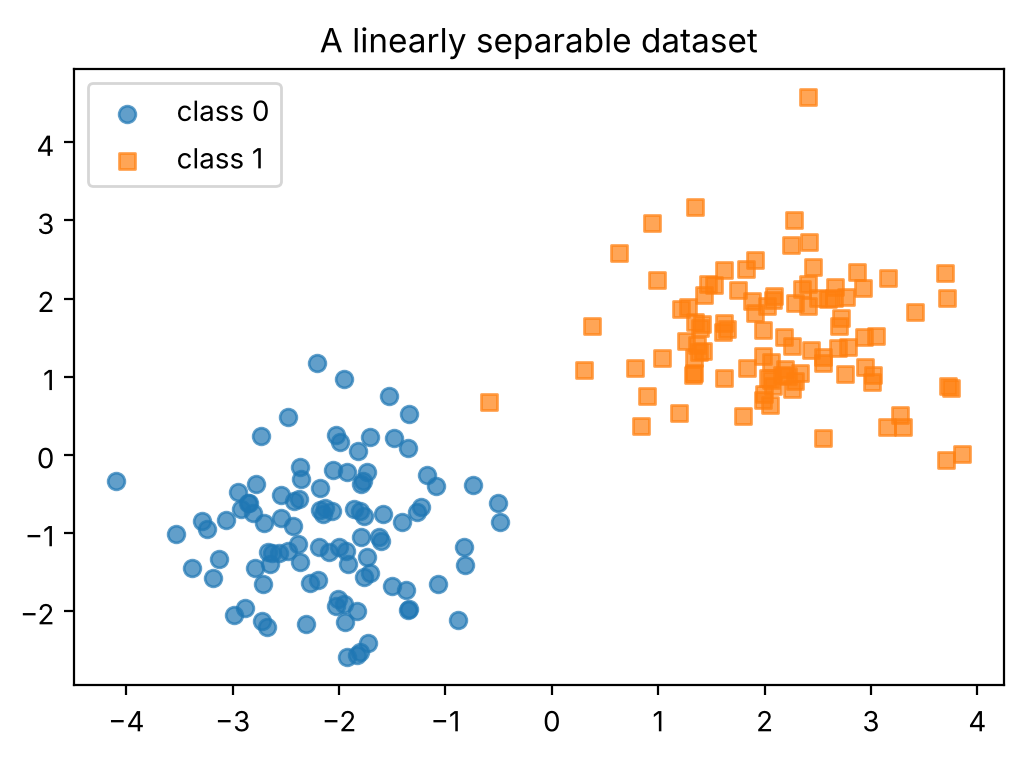

In [3]:
# Two Gaussian blobs that are linearly separable
n = 100
X0 = np.random.randn(n, 2) * 0.8 + np.array([-2, -1])
X1 = np.random.randn(n, 2) * 0.8 + np.array([2, 1.5])
X = np.vstack([X0, X1])
y = np.array([0] * n + [1] * n)

plt.scatter(X[y == 0, 0], X[y == 0, 1], label='class 0', alpha=0.7)
plt.scatter(X[y == 1, 0], X[y == 1, 1], label='class 1', alpha=0.7, marker='s')
plt.legend(); plt.title('A linearly separable dataset'); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

حالا کلاس `Perceptron` را پیاده‌سازی می‌کنیم. هر بار عبور کامل از روی داده‌ها را یک **Epoch** می‌نامیم. در هر Epoch ترتیب نمونه‌ها را تصادفی (Shuffle) می‌کنیم و تعداد خطاها را ثبت می‌کنیم.

</div>

In [4]:
class Perceptron:
    def __init__(self, n_features, lr=0.1):
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.lr = lr

    def predict(self, X):
        return step(X @ self.w + self.b)

    def fit(self, X, y, epochs=20):
        history = []
        for epoch in range(epochs):
            errors = 0
            for i in np.random.permutation(len(X)):
                y_hat = self.predict(X[i:i + 1])[0]
                update = self.lr * (y[i] - y_hat)
                self.w += update * X[i]
                self.b += update
                errors += int(update != 0)
            history.append(errors)
            if errors == 0:          # converged: every sample classified correctly
                break
        return history


perceptron = Perceptron(n_features=2, lr=0.1)
history = perceptron.fit(X, y)
print('errors per epoch:', history)
print('learned w =', perceptron.w, ' b =', round(perceptron.b, 3))

errors per epoch: [3, 1, 0]
learned w = [0.16435526 0.25118669]  b = 0.0


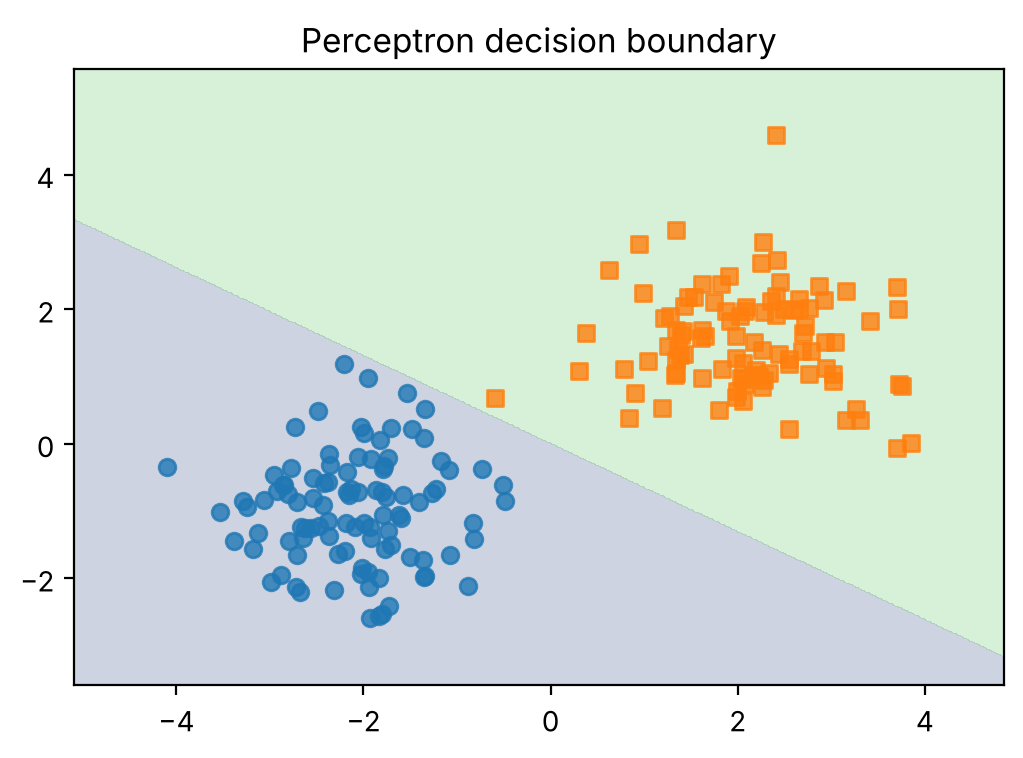

In [5]:
def plot_decision_boundary(predict_fn, X, y, title='', ax=None, h=0.02):
    """Colour the plane by the model's prediction and overlay the data points."""
    ax = ax or plt.gca()
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    zz = predict_fn(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, levels=[-0.5, 0.5, 1.5])
    ax.scatter(X[y == 0, 0], X[y == 0, 1], alpha=0.8)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], alpha=0.8, marker='s')
    ax.set_title(title)


plot_decision_boundary(perceptron.predict, X, y, 'Perceptron decision boundary')
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۴. مسئله XOR: محدودیت مدل خطی

در سال ۱۹۶۹ مینسکی و پاپرت در کتاب *Perceptrons* نشان دادند که پرسپترون تک‌لایه حتی تابع ساده **XOR** را نمی‌تواند یاد بگیرد. این یافته یکی از عوامل «زمستان هوش مصنوعی» اول بود. دلیلش هندسی است: هیچ خط راستی وجود ندارد که نقاط $(0,1)$ و $(1,0)$ را از $(0,0)$ و $(1,1)$ جدا کند.

بیایید این را تجربی ببینیم:

</div>

In [6]:
y_xor = np.array([0, 1, 1, 0])
p_xor = Perceptron(n_features=2, lr=0.1)
hist_xor = p_xor.fit(X_gate.astype(float), y_xor, epochs=100)

print('errors in the last 10 epochs:', hist_xor[-10:])
print('predictions:', p_xor.predict(X_gate), ' targets:', y_xor)

errors in the last 10 epochs: [4, 4, 3, 2, 3, 4, 3, 4, 4, 4]
predictions: [1 1 1 1]  targets: [0 1 1 0]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

تعداد خطاها هیچ‌وقت صفر نمی‌شود و الگوریتم بین جواب‌های غلط نوسان می‌کند.

**راه‌حل:** چند نورون را در **لایه‌های پشت سر هم** قرار دهیم. XOR را می‌توان این‌طور نوشت:

$$\text{XOR}(x_1, x_2) = \text{AND}\big(\text{OR}(x_1, x_2),\ \text{NOT AND}(x_1, x_2)\big)$$

یعنی یک **لایه پنهان (Hidden Layer)** با دو نورون (OR و NAND) و یک نورون خروجی (AND). این اولین **پرسپترون چندلایه (Multi-Layer Perceptron, MLP)** ماست:

</div>

MLP predictions: [0 1 1 0]  targets: [0 1 1 0]


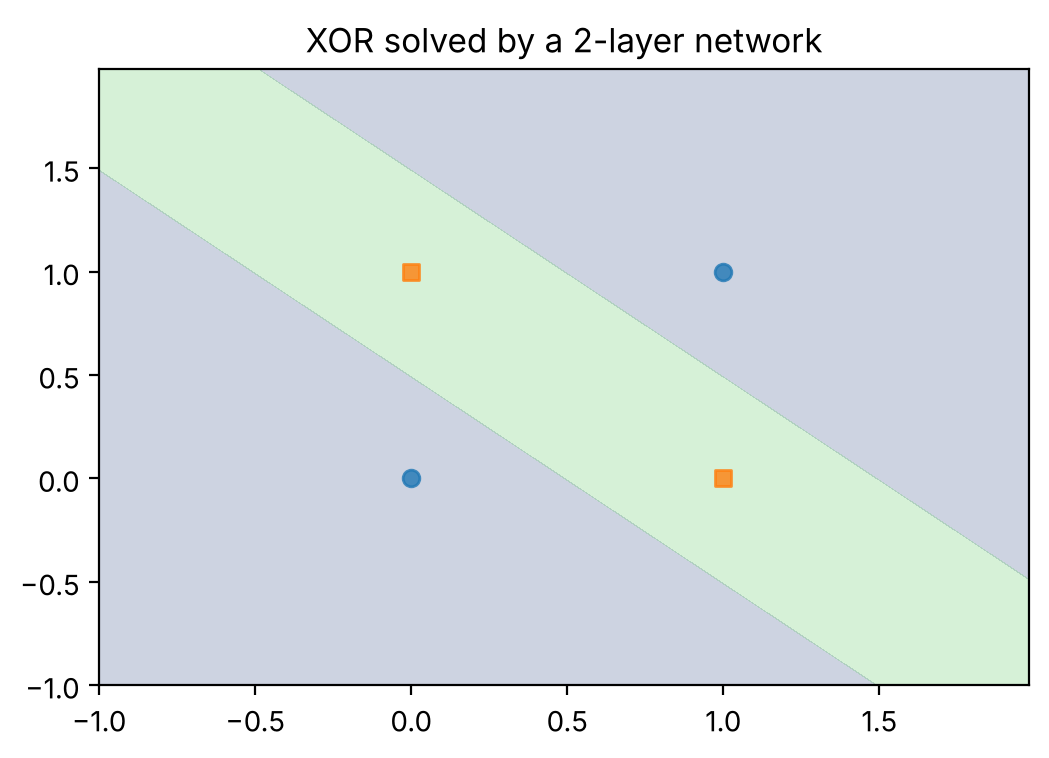

In [7]:
def xor_mlp(X):
    # hidden layer: two neurons (OR and NAND)
    W1 = np.array([[1.0, -1.0],
                   [1.0, -1.0]])
    b1 = np.array([-0.5, 1.5])
    h = step(X @ W1 + b1)
    # output layer: one neuron (AND)
    w2 = np.array([1.0, 1.0])
    b2 = -1.5
    return step(h @ w2 + b2)


print('MLP predictions:', xor_mlp(X_gate), ' targets:', y_xor)
plot_decision_boundary(xor_mlp, X_gate.astype(float), y_xor, 'XOR solved by a 2-layer network')
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

لایه پنهان، داده را به یک **فضای جدید** می‌برد که در آن مسئله خطی‌جداپذیر می‌شود. این همان ایده اصلی یادگیری عمیق است: **هر لایه نمایش جدیدی از داده می‌سازد**.

اما یک مشکل داریم: وزن‌ها را باز هم دستی تعیین کردیم. برای یادگیری خودکار وزن‌ها در شبکه چندلایه به **گرادیان** نیاز داریم و تابع پله‌ای مشتق مفیدی ندارد (مشتقش تقریباً همه‌جا صفر است). پس باید آن را با توابع **مشتق‌پذیر** جایگزین کنیم.

## ۵. توابع فعال‌سازی (Activation Functions)

| تابع | فرمول | برد خروجی | نکته |
|---|---|---|---|
| Sigmoid | $\sigma(z) = \frac{1}{1+e^{-z}}$ | $(0, 1)$ | برای خروجی احتمال باینری؛ در لایه‌های پنهان دچار Vanishing Gradient می‌شود |
| Tanh | $\tanh(z)$ | $(-1, 1)$ | صفرمرکز (Zero-centered)؛ در RNNها رایج است |
| ReLU | $\max(0, z)$ | $[0, \infty)$ | ساده و سریع؛ پیش‌فرض لایه‌های پنهان |
| Leaky ReLU | $\max(\alpha z, z)$ | $(-\infty, \infty)$ | مشکل «نورون مرده» (Dying ReLU) را کم می‌کند |
| GELU | $z\,\Phi(z)$ | تقریباً $(-0.17, \infty)$ | استاندارد مدل‌های Transformer مثل BERT و GPT |

</div>

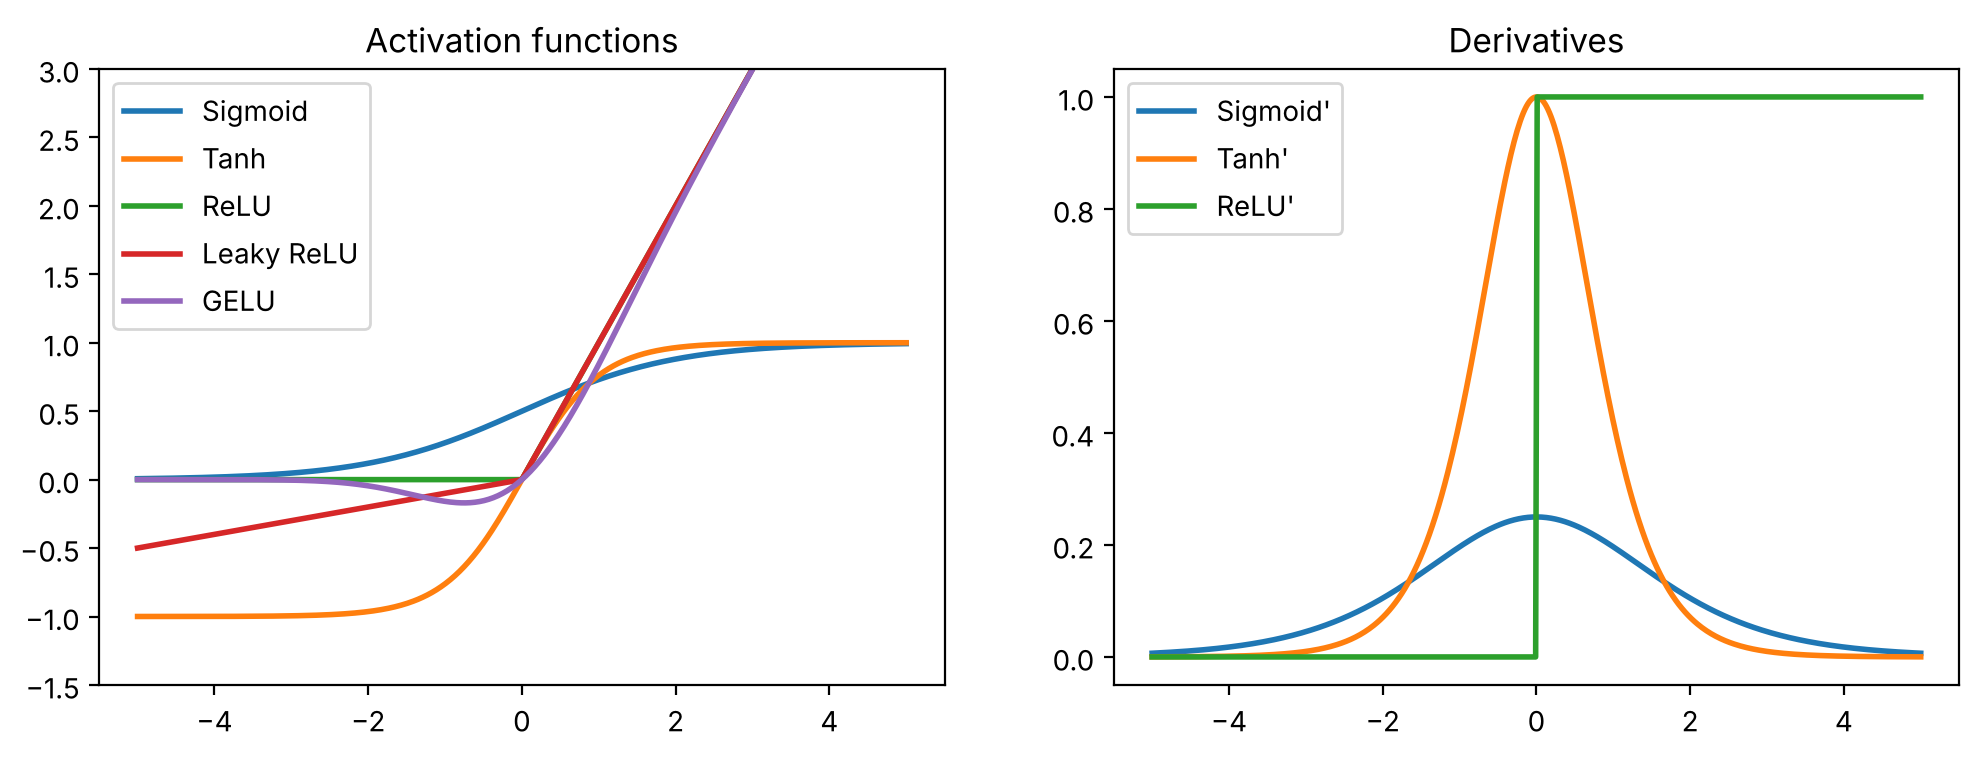

In [8]:
def sigmoid(z):     return 1 / (1 + np.exp(-z))
def tanh(z):        return np.tanh(z)
def relu(z):        return np.maximum(0, z)
def leaky_relu(z):  return np.where(z > 0, z, 0.1 * z)
def gelu(z):        return 0.5 * z * (1 + np.tanh(np.sqrt(2 / np.pi) * (z + 0.044715 * z ** 3)))

# derivatives (needed for training in session 2)
def d_sigmoid(z):   s = sigmoid(z); return s * (1 - s)
def d_tanh(z):      return 1 - np.tanh(z) ** 2
def d_relu(z):      return (z > 0).astype(float)

z = np.linspace(-5, 5, 500)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for f, name in [(sigmoid, 'Sigmoid'), (tanh, 'Tanh'), (relu, 'ReLU'), (leaky_relu, 'Leaky ReLU'), (gelu, 'GELU')]:
    axes[0].plot(z, f(z), label=name, lw=2)
for f, name in [(d_sigmoid, "Sigmoid'"), (d_tanh, "Tanh'"), (d_relu, "ReLU'")]:
    axes[1].plot(z, f(z), label=name, lw=2)
axes[0].set_ylim(-1.5, 3); axes[0].set_title('Activation functions'); axes[0].legend()
axes[1].set_title('Derivatives'); axes[1].legend()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

به نمودار مشتق‌ها دقت کنید: بیشینه مشتق Sigmoid فقط $0.25$ است و برای $|z|$ بزرگ تقریباً صفر می‌شود (**اشباع یا Saturation**). در جلسه بعد می‌بینیم که در شبکه‌های عمیق این گرادیان‌های کوچک در هم ضرب می‌شوند و به صفر میل می‌کنند؛ پدیده‌ای که **محوشدگی گرادیان (Vanishing Gradient)** نام دارد. مشتق ReLU برای ورودی مثبت همیشه ۱ است و همین یکی از دلایل موفقیت آن است.

### چرا غیرخطی بودن ضروری است؟

اگر تابع فعال‌سازی نداشته باشیم (یا خطی باشد)، چند لایه پشت سر هم معادل **یک لایه خطی** است:

$$W_2(W_1\mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2 = \underbrace{(W_2W_1)}_{W}\mathbf{x} + \underbrace{(W_2\mathbf{b}_1 + \mathbf{b}_2)}_{\mathbf{b}}$$

یعنی عمق شبکه هیچ قدرت اضافه‌ای ایجاد نمی‌کند. بیایید عددی بررسی کنیم:

</div>

In [9]:
W1, b1 = np.random.randn(4, 3), np.random.randn(4)
W2, b2 = np.random.randn(2, 4), np.random.randn(2)
x = np.random.randn(3)

two_linear_layers = W2 @ (W1 @ x + b1) + b2
one_linear_layer = (W2 @ W1) @ x + (W2 @ b1 + b2)
print('identical outputs:', np.allclose(two_linear_layers, one_linear_layer))

identical outputs: True


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۶. شبکه چندلایه (MLP) و Forward Pass

در یک MLP، هر لایه یک **ماتریس وزن** $W^{[l]}$ و **بردار بایاس** $\mathbf{b}^{[l]}$ دارد. برای پردازش هم‌زمان یک دسته (Batch) از نمونه‌ها، ورودی را به صورت ماتریس $X$ با ابعاد `(batch_size, n_features)` در نظر می‌گیریم:

$$H^{[l]} = \varphi\big(H^{[l-1]} W^{[l]} + \mathbf{b}^{[l]}\big), \qquad H^{[0]} = X$$

به محاسبه خروجی از روی ورودی، **انتشار رو به جلو (Forward Propagation)** می‌گوییم. برای مسائل طبقه‌بندی چندکلاسه، لایه آخر از تابع **Softmax** استفاده می‌کند تا خروجی‌ها به توزیع احتمال تبدیل شوند:

$$\text{softmax}(\mathbf{z})_k = \frac{e^{z_k}}{\sum_j e^{z_j}}$$

به خروجی‌های قبل از Softmax، **لاجیت (Logits)** گفته می‌شود.

</div>

In [10]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)          # subtract the max for numerical stability
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


class MLP:
    """A fully connected network with ReLU hidden layers and a softmax output."""

    def __init__(self, layer_sizes, seed=0):
        rng = np.random.default_rng(seed)
        self.params = []
        for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
            W = rng.normal(0, np.sqrt(2 / n_in), size=(n_in, n_out))   # He initialisation (session 5)
            b = np.zeros(n_out)
            self.params.append((W, b))

    def forward(self, X):
        h = X
        for i, (W, b) in enumerate(self.params):
            z = h @ W + b
            h = relu(z) if i < len(self.params) - 1 else softmax(z)
        return h

    def n_parameters(self):
        return sum(W.size + b.size for W, b in self.params)


mlp = MLP([4, 16, 8, 3])
X_batch = np.random.randn(5, 4)                   # a batch of 5 samples with 4 features
probs = mlp.forward(X_batch)
print('output shape:', probs.shape)
print('row sums    :', probs.sum(axis=1).round(6))
print('parameters  :', mlp.n_parameters())

output shape: (5, 3)
row sums    : [1. 1. 1. 1. 1.]
parameters  : 243


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ذهنی:** تعداد پارامترهای شبکه `[4, 16, 8, 3]` را دستی حساب کنید:
$(4\times16+16) + (16\times8+8) + (8\times3+3) = 80 + 136 + 27 = 243$.

این شبکه هنوز آموزش ندیده و خروجی‌اش تصادفی است. در جلسه بعد با **پس‌انتشار خطا (Backpropagation)** آن را آموزش می‌دهیم.

## ۷. شهود قضیه تقریب جهانی (Universal Approximation Theorem)

این قضیه (Cybenko 1989; Hornik 1991) می‌گوید یک شبکه با **فقط یک لایه پنهان** و تعداد کافی نورون می‌تواند هر تابع پیوسته‌ای را روی یک بازه محدود با دقت دلخواه تقریب بزند.

شهود آن با ReLU ساده است: هر نورون ReLU یک «شکستگی» در نمودار ایجاد می‌کند و جمع وزن‌دار تعداد زیادی از این شکستگی‌ها می‌تواند هر منحنی را تقریب بزند. در آزمایش زیر محل شکستگی نورون‌ها را تصادفی انتخاب می‌کنیم و فقط **وزن‌های لایه خروجی** را با کمترین مربعات (Least Squares) پیدا می‌کنیم:

</div>

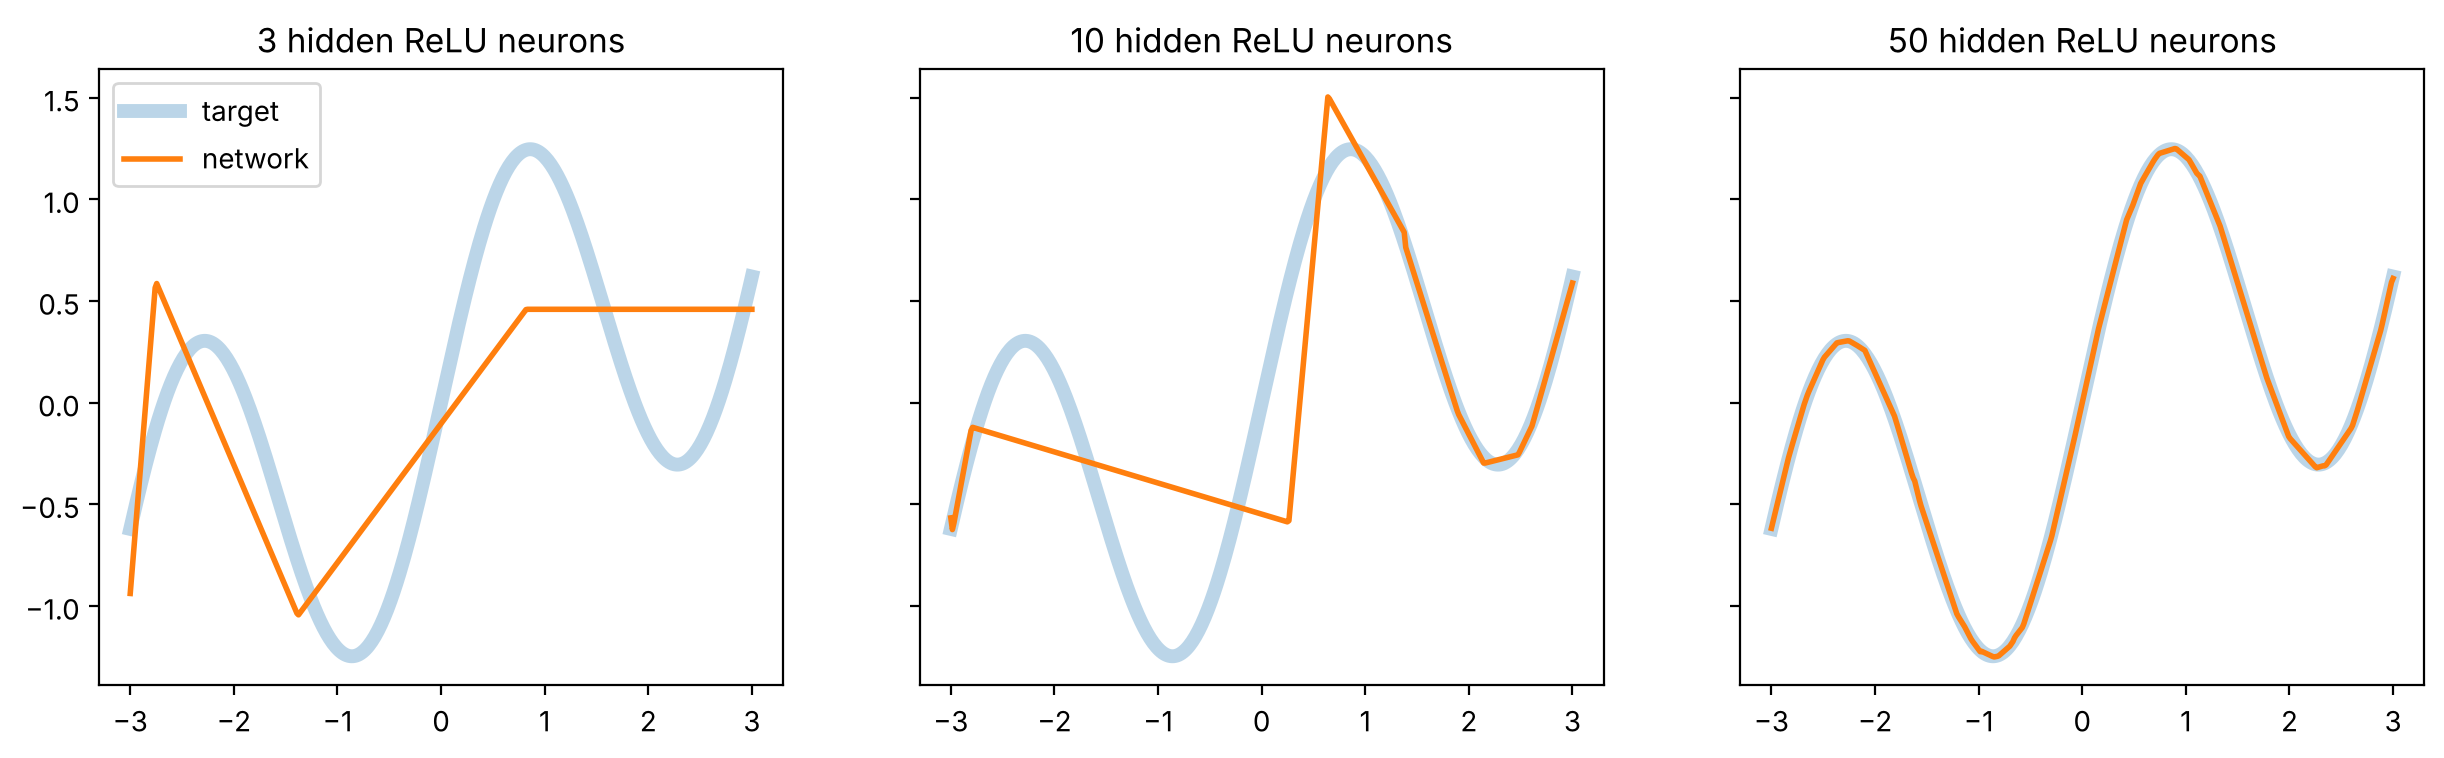

In [11]:
x = np.linspace(-3, 3, 400)
target = np.sin(2 * x) + 0.3 * x
rng = np.random.default_rng(0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, n_hidden in zip(axes, [3, 10, 50]):
    breakpoints = rng.uniform(-3, 3, n_hidden)
    signs = rng.choice([-1, 1], n_hidden)
    H = relu(signs * (x[:, None] - breakpoints))   # hidden-layer activations, shape (400, n_hidden)
    H = np.c_[H, np.ones_like(x)]                  # bias column
    w_out, *_ = np.linalg.lstsq(H, target, rcond=None)
    ax.plot(x, target, lw=5, alpha=0.3, label='target')
    ax.plot(x, H @ w_out, lw=2, label='network')
    ax.set_title(f'{n_hidden} hidden ReLU neurons')
axes[0].legend()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با افزایش تعداد نورون‌ها تقریب بهتر می‌شود. دو نکته مهم:

- این قضیه فقط **وجود** چنین شبکه‌ای را تضمین می‌کند؛ نمی‌گوید چطور وزن‌ها را پیدا کنیم و نمی‌گوید چند نورون لازم است.
- در عمل، شبکه‌های **عمیق‌تر** (لایه‌های بیشتر) معمولاً با پارامترهای بسیار کمتری نسبت به شبکه‌های **پهن** (نورون‌های بیشتر در یک لایه) به همان دقت می‌رسند. به همین دلیل به این حوزه «یادگیری **عمیق**» می‌گوییم.

## جمع‌بندی

- نورون مصنوعی: جمع وزن‌دار ورودی‌ها به‌علاوه بایاس و عبور از تابع فعال‌سازی.
- پرسپترون یک طبقه‌بند خطی است و قانون یادگیری ساده‌ای دارد، اما XOR را حل نمی‌کند.
- با افزودن لایه پنهان، شبکه نمایش جدیدی از داده می‌سازد و مسائل غیرخطی قابل حل می‌شوند.
- بدون تابع فعال‌سازی غیرخطی، شبکه عمیق معادل یک لایه خطی است. ReLU پیش‌فرض لایه‌های پنهان و Softmax رایج‌ترین خروجی برای طبقه‌بندی است.
- MLP با یک لایه پنهان در تئوری تقریب‌زننده جهانی است، اما در عمل عمق کارآمدتر است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. وزن‌ها و بایاس یک پرسپترون را طوری تعیین کنید که تابع NAND را پیاده کند. چرا NAND به‌تنهایی برای ساخت هر مدار منطقی کافی است؟

۲. کلاس `Perceptron` را روی داده‌ای اجرا کنید که دو خوشه آن کمی هم‌پوشانی دارند (مثلاً مراکز را به هم نزدیک کنید). چه اتفاقی برای نمودار تعداد خطا در هر Epoch می‌افتد؟

۳. تعداد پارامترهای یک MLP با ساختار `[784, 256, 128, 10]` (طبقه‌بندی تصاویر ۲۸×۲۸) را حساب کنید و با `MLP(...).n_parameters()` بررسی کنید.

۴. در آزمایش تقریب جهانی، تابع هدف را به $|x|$ و سپس به یک تابع پله‌ای تغییر دهید. کدام سخت‌تر تقریب زده می‌شود و چرا؟

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** وزن‌ها و بایاس یک پرسپترون را طوری تعیین کنید که تابع NAND را پیاده کند. چرا NAND به‌تنهایی برای ساخت هر مدار منطقی کافی است؟

</div>

In [12]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** کلاس `Perceptron` را روی داده‌ای اجرا کنید که دو خوشه آن کمی هم‌پوشانی دارند (مثلاً مراکز را به هم نزدیک کنید). چه اتفاقی برای نمودار تعداد خطا در هر Epoch می‌افتد؟

</div>

In [13]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** تعداد پارامترهای یک MLP با ساختار `[784, 256, 128, 10]` (طبقه‌بندی تصاویر ۲۸×۲۸) را حساب کنید و با `MLP(...).n_parameters()` بررسی کنید.

</div>

In [14]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** در آزمایش تقریب جهانی، تابع هدف را به $|x|$ و سپس به یک تابع پله‌ای تغییر دهید. کدام سخت‌تر تقریب زده می‌شود و چرا؟

</div>

In [15]:
# پاسخ خود را اینجا بنویسید
